In [ ]:
%pip install -U agentops

In [1]:
import agentops
from langgraph.graph import StateGraph, START, END
from langchain_openai import ChatOpenAI
from langchain_tavily import TavilySearch
from dotenv import load_dotenv
import os
import re


from typing import TypedDict, List, Dict, Any


In [2]:
import os
from dotenv import load_dotenv

# Carregar o arquivo .env
load_dotenv(
    r"C:\Users\eugen\Documents\ProjetoIA\.env",
    override=True
)

# Verificar configurações
print("OpenAI:", bool(os.getenv("OPENAI_API_KEY")))
print("Tavily:", bool(os.getenv("TAVILY_API_KEY")))
print("AgentOps:", bool(os.getenv("AGENTOPS_API_KEY")))

OpenAI: True
Tavily: True
AgentOps: True


In [3]:
import agentops
from dotenv import load_dotenv

# Carregar variáveis de ambiente
load_dotenv(
    r"C:\Users\eugen\Documents\ProjetoIA\.env",
    override=True
)
agentops.init(api_key=os.environ['AGENTOPS_API_KEY'], default_tags=["langgraph-agent"])

🖇 AgentOps: You're on the agentops free plan 🤔
--- Logging error ---
Traceback (most recent call last):
  File "C:\Users\eugen\AppData\Local\Programs\Python\Python312\Lib\logging\__init__.py", line 1163, in emit
    stream.write(msg + self.terminator)
  File "C:\Users\eugen\AppData\Local\Programs\Python\Python312\Lib\encodings\cp1252.py", line 19, in encode
    return codecs.charmap_encode(input,self.errors,encoding_table)[0]
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
UnicodeEncodeError: 'charmap' codec can't encode character '\U0001f914' in position 66: character maps to <undefined>
Call stack:
  File "C:\Users\eugen\AppData\Local\Programs\Python\Python312\Lib\runpy.py", line 198, in _run_module_as_main
    return _run_code(code, main_globals, None,
  File "C:\Users\eugen\AppData\Local\Programs\Python\Python312\Lib\runpy.py", line 88, in _run_code
    exec(code, run_globals)
  File "c:\Users\eugen\Documents\agentops-env-312\Lib\site-packages\ipykernel_launcher.

In [24]:
class AgentState(TypedDict):
    query: str
    search_results: str
    summary: str
    final_answer: str

In [25]:
# Inicializar o modelo da OpenAI
model = ChatOpenAI(model_name="gpt-4o-mini", temperature=0)

# Inicializar o Tavily Search
from langchain_tavily import TavilySearch

search = TavilySearch(max_results=3)

In [35]:

from langchain_tavily import TavilySearch
from agentops.sdk.decorators import tool as agentops_tool

@agentops_tool(name="web_search")
def web_search(state: AgentState) -> AgentState:
    """Realiza buscas na internet utilizando Tavily."""

    try:
        # Inicializar Tavily
        tavily_search = TavilySearch(
            max_results=3,
            search_depth="advanced"
        )

        # Realizar pesquisa
        search_results = tavily_search.invoke({
            "query": state["query"]
        })

        # Extrair resultados
        if isinstance(search_results, dict):
            results = search_results.get("results", [])
        elif isinstance(search_results, list):
            results = search_results
        else:
            results = [search_results]

        # Formatar resultados
        formatted_results = "\n".join(
            f"{r.get('title', '')}: {r.get('content', '')}"
            if isinstance(r, dict) else str(r)
            for r in results
        )

        state["search_results"] = (
            formatted_results or "Nenhum resultado encontrado."
        )

    except Exception as e:
        print(f"Erro no Tavily: {e}")
        raise

    return state


In [27]:

from agentops.sdk.decorators import operation
from langchain_core.prompts import ChatPromptTemplate

# Registrar operação no AgentOps
@operation(name="summarize_results")
def summarize_results(state: AgentState) -> AgentState:
    """Resume os resultados da pesquisa utilizando LLM."""

    # Criar prompt
    prompt = ChatPromptTemplate.from_template(
        "Resuma as seguintes informações em um parágrafo "
        "conciso em português.\n\n"
        "Informações: {search_results}"
    )

    # Criar cadeia de processamento
    chain = prompt | model

    # Executar modelo
    summary = chain.invoke({
        "search_results": state["search_results"]
    }).content

    # Atualizar estado
    state["summary"] = summary

    return state


In [28]:
from typing import TypedDict

# Definir o estado do agente
class AgentState(TypedDict):
    query: str
    search_results: str
    summary: str
    final_answer: str


from agentops.sdk.decorators import operation
from langchain_core.prompts import ChatPromptTemplate

@operation(name="generate_answer")
def generate_answer(state: AgentState) -> dict:
    """Gera a resposta final utilizando o LLM."""

    prompt = ChatPromptTemplate.from_template(
        "Com base na pergunta '{query}' e nas informações "
        "resumidas abaixo, forneça uma resposta detalhada "
        "em português.\n\nResumo: {summary}"
    )

    chain = prompt | model

    final_answer = chain.invoke({
        "query": state["query"],
        "summary": state["summary"]
    }).content

    return {"final_answer": final_answer}

In [43]:
from langgraph.graph import StateGraph, START, END

# Construir workflow
workflow = StateGraph(AgentState)

workflow.add_node("web_search", web_search)
workflow.add_node("summarize_results", summarize_results)
workflow.add_node("generate_answer", generate_answer)

workflow.add_edge(START, "web_search")
workflow.add_edge("web_search", "summarize_results")
workflow.add_edge("summarize_results", "generate_answer")
workflow.add_edge("generate_answer", END)

graph = workflow.compile()

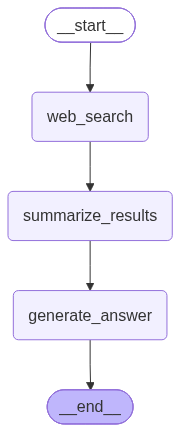

In [37]:
from IPython.display import Image, display

display(Image(graph.get_graph().draw_mermaid_png()))

In [39]:

import agentops

def execute_workflow(query: str) -> str:
    """Executa o workflow e registra o rastreamento no AgentOps."""

    # Definir estado inicial
    initial_state = AgentState(
        query=query,
        search_results="",
        summary="",
        final_answer=""
    )

    # Iniciar rastreamento do AgentOps
    trace_context = agentops.start_trace(
        "langgraph-workflow",
        tags=["langgraph-agent"]
    )

    if trace_context is None:
        raise RuntimeError("AgentOps não foi inicializado corretamente.")

    try:
        # Executar o grafo
        final_state = graph.invoke(initial_state)

        # Verificar os campos retornados
        print("Campos retornados:", list(final_state.keys()))

        # Verificar resposta final
        if not final_state.get("final_answer"):
            raise RuntimeError(
                "O nó generate_answer não produziu uma resposta final."
            )

        # Retornar resposta final
        return final_state["final_answer"]

    except Exception:
        # Encerrar rastreamento com erro
        agentops.end_trace(trace_context, end_state="Error")
        raise

    finally:
        # Encerrar rastreamento com sucesso somente se não houve erro
        pass


In [40]:

import agentops

def execute_workflow(query: str) -> str:
    """Executa o workflow e registra o rastreamento no AgentOps."""

    # Definir estado inicial
    initial_state = AgentState(
        query=query,
        search_results="",
        summary="",
        final_answer=""
    )

    # Iniciar rastreamento do AgentOps
    trace_context = agentops.start_trace(
        "langgraph-workflow",
        tags=["langgraph-agent"]
    )

    if trace_context is None:
        raise RuntimeError("AgentOps não foi inicializado corretamente.")

    try:
        # Executar o grafo
        final_state = graph.invoke(initial_state)

        # Verificar campos retornados
        print("Campos retornados:", list(final_state.keys()))

        # Verificar resposta final
        if not final_state.get("final_answer"):
            raise RuntimeError(
                "O nó generate_answer não produziu uma resposta final."
            )

        answer = final_state["final_answer"]

    except Exception:
        agentops.end_trace(trace_context, end_state="Error")
        raise

    else:
        agentops.end_trace(trace_context, end_state="Success")
        return answer


In [41]:


# Definir o estado do agente
class AgentState(TypedDict):
    query: str
    search_results: str
    summary: str
    final_answer: str



In [46]:

# Exemplo de consulta
query = "Quais são os cursos de engenharia que existem?"

# Executar fluxo de trabalho
answer = execute_workflow(query)

# Exibir resposta final
print("Resposta Final:\n")
print(answer)

🖇 AgentOps: Session Replay for langgraph-workflow trace: https://app.agentops.ai/sessions?trace_id=21424fe2fdf3a66bcf88b6e9d983a4bc


Campos retornados: ['query', 'search_results', 'summary', 'final_answer']


🖇 AgentOps: Session Replay for langgraph-workflow.session trace: https://app.agentops.ai/sessions?trace_id=21424fe2fdf3a66bcf88b6e9d983a4bc


Resposta Final:

No Brasil, a área de engenharia é bastante ampla e diversificada, com mais de 50 tipos de cursos disponíveis, cada um com suas particularidades e focos específicos. Todos esses cursos compartilham uma base sólida em cálculos e ciências exatas, o que é fundamental para a formação de engenheiros competentes e preparados para enfrentar os desafios do mercado.

Os cinco cursos de engenharia mais procurados, que se destacam pelo número de profissionais formados e pela demanda no mercado de trabalho, são:

1. **Engenharia Civil**: Este curso é voltado para a construção e manutenção de obras de infraestrutura, como edifícios, pontes, estradas e barragens. Os engenheiros civis são responsáveis por projetar, planejar e executar obras, garantindo a segurança e a funcionalidade das construções.

2. **Engenharia de Produção**: Focado na otimização de processos produtivos, este curso combina conhecimentos de engenharia, administração e economia. Os engenheiros de produção trabalham